# Stimulus lag of the RF fit

The RF fits (`cottage_analysis.analysis.spheres.rf_fitting.fit_3d_rfs`, `shift_stim=2`) regress the response of imaging frame
*t* on the stimulus at the start of frame *t* − 2, a lag of **2 frames (131 ms at 15.2 Hz)**. The paper RFs are fitted on
deconvolved spikes (τ 1.1 s GCaMP6s, 0.25 s GCaMP6f, see `tau_estimation.ipynb`) with this lag (`precompute_data/rf_fit_spikes.py`).

To check the lag, the RF fit was redone at whole-frame lags (Oct 2026, NEMO), with the hyperparameter search of the pipeline
at every lag, on the 5 multidepth sessions:

- multidepth recordings (`latency_sweep.py --model snapshot`): cells with R² > 0.05 in a previous fit, lags 0–20 frames on
  dF/F, 0–10 on spikes;
- single-depth recordings (`single_depth_lag_sweep.py`): cells with a pipeline single-depth R² > 0.03, same lags.

For each cell, held-out R² at each lag is divided by its best R² over lags; curves are the median over cells.
`data/lag_sweep/lag_sweep_summary.csv` holds these summaries only (`summarise_lag_sweeps.py`).

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

COL = {"GCaMP6s": "#2a78d6", "GCaMP6f": "#eb6834"}
LS = {"multidepth": "-", "single_depth": "--"}
LAG = 2
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 120,
        "savefig.dpi": 120,
    }
)
t = pd.read_csv("data/lag_sweep/lag_sweep_summary.csv")

## R² against lag

Left: dF/F. Right: spikes. Top: mean of the session curves of each indicator, multidepth and single depth together.
Bottom: one curve per session (solid: multidepth, dashed: single depth). Dotted line: the lag of the fits.

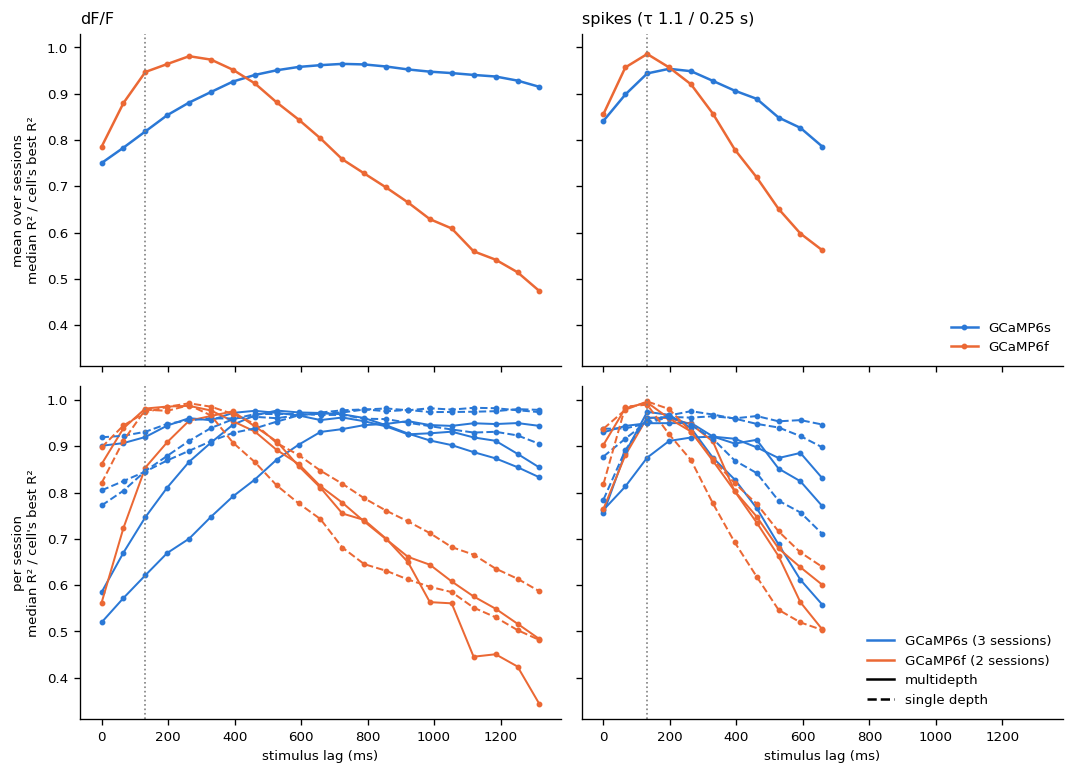

In [ ]:
from matplotlib.lines import Line2D

fig, axs = plt.subplots(2, 2, figsize=(9, 6.5), sharex=True, sharey=True)
for col, sig in enumerate(["dff", "spikes"]):
    d = t[t.signal == sig]
    for ind in COL:
        m = (
            d[d.indicator == ind]
            .groupby("lag_frames")[["lag_ms", "median_r2_rel_best"]]
            .mean()
        )
        axs[0, col].plot(
            m.lag_ms,
            m.median_r2_rel_best,
            marker="o",
            ms=2.5,
            lw=1.5,
            c=COL[ind],
            label=ind,
        )
    for (rec, s), g in d.groupby(["recording", "session"]):
        axs[1, col].plot(
            g.lag_ms,
            g.median_r2_rel_best,
            LS[rec],
            marker="o",
            ms=2.5,
            lw=1.2,
            c=COL[g.indicator.iloc[0]],
        )
    axs[0, col].set_title(
        "dF/F" if sig == "dff" else "spikes (τ 1.1 / 0.25 s)", loc="left"
    )
    axs[1, col].set_xlabel("stimulus lag (ms)")
for ax in axs.flat:
    ax.axvline(t.lag_ms[t.lag_frames == LAG].iloc[0], c="0.5", ls=":", lw=1)
axs[0, 0].set_ylabel("mean over sessions\nmedian R² / cell's best R²")
axs[1, 0].set_ylabel("per session\nmedian R² / cell's best R²")
axs[0, 1].legend(frameon=False, loc="lower right")
axs[1, 1].legend(
    handles=[
        Line2D([], [], c=COL["GCaMP6s"], label="GCaMP6s (3 sessions)"),
        Line2D([], [], c=COL["GCaMP6f"], label="GCaMP6f (2 sessions)"),
        Line2D([], [], c="k", ls="-", label="multidepth"),
        Line2D([], [], c="k", ls="--", label="single depth"),
    ],
    frameon=False,
    loc="lower right",
)
fig.tight_layout()

## Best lag and R² at the lag used

Per session: lag of the peak of the median curve, median R² / best at 2 frames, and fraction of cells whose best lag is
within 1 frame of 2 (1–3 frames).

In [ ]:
rows = []
for (rec, sig, s), g in t.groupby(["recording", "signal", "session"]):
    rows.append(
        dict(
            recording=rec,
            signal=sig,
            session=s,
            indicator=g.indicator.iloc[0],
            n_cells=g.n_cells.iloc[0],
            peak_ms=g.lag_ms[g.median_r2_rel_best.idxmax()],
            r2_rel_best_at_lag2=g.median_r2_rel_best[g.lag_frames == LAG].iloc[0],
            frac_best_lag_1_3=g.frac_best_lag[g.lag_frames.between(1, 3)].sum(),
        )
    )
summary = pd.DataFrame(rows).sort_values(
    ["signal", "recording", "indicator", "session"]
)
summary.round(2)

,recording,signal,session,indicator,n_cells,peak_ms,r2_rel_best_at_lag2,frac_best_lag_1_3
3,multidepth,dff,PZAH17.1e_S20250313,GCaMP6f,37,394.9,0.85,0.14
4,multidepth,dff,PZAH17.1e_S20250318,GCaMP6f,60,263.3,0.98,0.43
0,multidepth,dff,PZAG16.3b_S20250317,GCaMP6s,192,921.5,0.62,0.01
1,multidepth,dff,PZAG16.3c_S20250317,GCaMP6s,150,526.6,0.75,0.01
2,multidepth,dff,PZAG17.3a_S20250319,GCaMP6s,27,460.8,0.92,0.07
13,single_depth,dff,PZAH17.1e_S20250313,GCaMP6f,37,263.3,0.98,0.51
14,single_depth,dff,PZAH17.1e_S20250318,GCaMP6f,54,263.3,0.97,0.41
10,single_depth,dff,PZAG16.3b_S20250317,GCaMP6s,179,1251.0,0.85,0.00
11,single_depth,dff,PZAG16.3c_S20250317,GCaMP6s,200,592.7,0.85,0.02
12,single_depth,dff,PZAG17.3a_S20250319,GCaMP6s,49,1120.0,0.93,0.04


In [ ]:
print(
    summary.groupby(["signal", "recording", "indicator"])[
        ["peak_ms", "r2_rel_best_at_lag2"]
    ]
    .agg(["min", "max"])
    .round(2)
)

                              peak_ms         r2_rel_best_at_lag2      
                                  min     max                 min   max
signal recording    indicator                                          
dff    multidepth   GCaMP6f     263.3   394.9                0.85  0.98
                    GCaMP6s     460.8   921.5                0.62  0.92
       single_depth GCaMP6f     263.3   263.3                0.97  0.98
                    GCaMP6s     592.7  1251.0                0.85  0.93
spikes multidepth   GCaMP6f     131.6   131.6                0.96  0.99
                    GCaMP6s     131.6   329.1                0.88  0.97
       single_depth GCaMP6f     131.6   131.6                0.99  1.00
                    GCaMP6s     197.6   461.0                0.95  0.96


## Best lag of each cell, spikes

Fraction of cells by best lag, pooled over sessions of each indicator (weighted by cells).

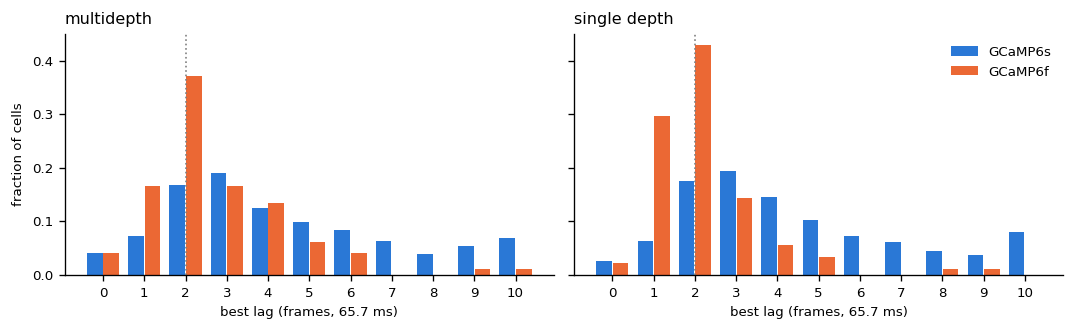

In [ ]:
sp = t[t.signal == "spikes"].assign(n_best=lambda d: d.frac_best_lag * d.n_cells)
fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, rec in zip(axs, ["multidepth", "single_depth"]):
    for k, ind in enumerate(COL):
        g = (
            sp[(sp.recording == rec) & (sp.indicator == ind)]
            .groupby("lag_frames")
            .n_best.sum()
        )
        ax.bar(
            g.index + (k - 0.5) * 0.4,
            g / g.sum(),
            width=0.38,
            color=COL[ind],
            label=ind,
        )
    ax.axvline(LAG, c="0.5", ls=":", lw=1)
    ax.set_xticks(range(0, 11))
    ax.set_xlabel("best lag (frames, 65.7 ms)")
    ax.set_title(rec.replace("_", " "), loc="left")
axs[0].set_ylabel("fraction of cells")
axs[1].legend(frameon=False)
fig.tight_layout()

## Conclusion

- **On spikes, 2 frames is at or near the best lag** for both indicators and both recording types: the median R² at lag 2 is
  ≥ 88 % of each cell's best in every session (≥ 95 % in all but one), and the median curves peak at 130–330 ms in multidepth,
  130–460 ms in single depth, where GCaMP6s curves are broad.
- Per cell, the best lag on spikes is concentrated at 1–3 frames for GCaMP6f, and spread over 2–10 frames for GCaMP6s, whose
  curves are flat: for these cells the lag barely changes R², so the median curve rather than each cell's best is the criterion.
- **On dF/F, the best lag is longer for GCaMP6s** (0.46–1.25 s, curves flat over several hundred ms) because of the slow calcium
  decay; GCaMP6f peaks at 260–400 ms. Deconvolution removes this indicator dependence, so a single lag fits all sessions.
- Lags are whole frames: within-frame timing (scan line of each ROI, up to 66 ms) is not modelled.

## Gratings: lag of the frame-level SF/TF fits (dF/F)

Is the lag of the RF and RS/OF fits right for the gratings? The frame-level running-speed models of the reviewer
grating analysis (`precompute_data/sftf_running_models.py`, main analysis at 5 frames on dF/F) pair the stimulus
and running speed of frame *t* with the dF/F of frame *t* + lag. `revisions/sftf/sftf_lag_sweep.py` refits `rsg_tf`
(SF, TF and direction tuning, running-speed Gaussian on the amplitude, TF preference shifted with running speed;
stimulus and running speed shifted together) and the `base` (no running speed) and `rsg` models it starts from, at
lags −2 to 15 frames, on running frames, held-out R² leaving one recording out (NEMO,
`/camp/home/blota/code/sftf_lag_sweep`). Cells: the 100 SF/TF-tuned cells with the highest held-out R² of the
trial-level SF/TF fit (0.52–0.85; a criterion with no frame lag, so it does not favour any lag; GCaMP6f, PZAH10.2d
and PZAH10.2f, 6 sessions), listed in `data/lag_sweep/sftf_lag_sweep_cells.csv`. Data (one row per cell and lag): `sftf_lag_sweep.csv` in
`fig_reviewer_gratings/lag_sweep/` of the figures folder (BlackPasspo).

Left: held-out R² / the cell's best R² over lags (grey: `rsg_tf`, one line per cell; black: `rsg_tf` median; dashed:
`base` median), with the GCaMP6f dF/F RF curve of the sweep above (mean of the two sessions, multidepth and single
depth). Middle: TF shift slope `a_tf` of `rsg_tf`. Right: preferred SF and TF of `rsg_tf` relative to the cell's
value at its best lag (median over cells). Dashed vertical line: lag 0; dotted: lag 5 (main analysis).


68 cells


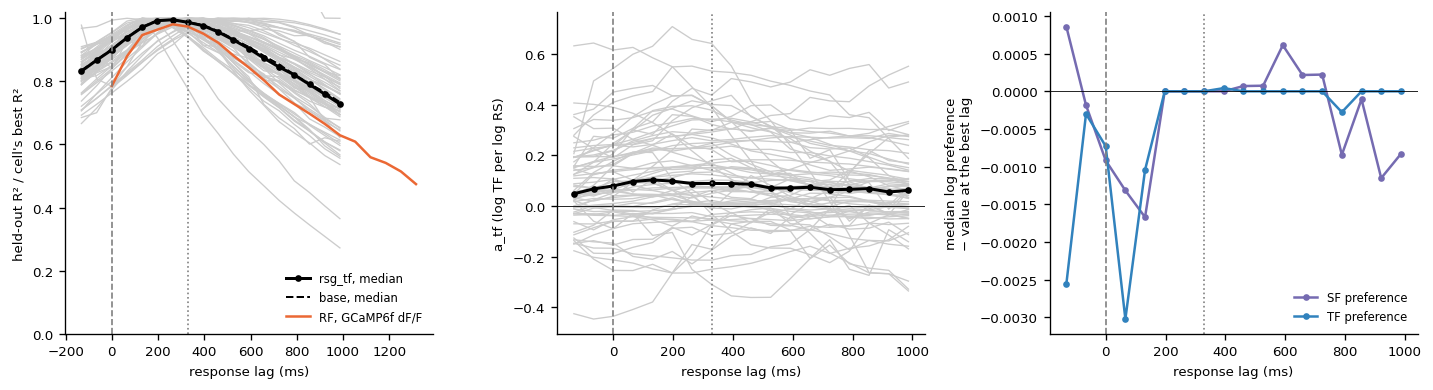

In [ ]:
import flexiznam as flz

from v1_depth_map.paths import get_figures_roots

_, GRATINGS_ROOT = get_figures_roots(
    flz.get_flexilims_session("hey2_3d-vision_foodres_20220101"),
    fig_subdir="fig_reviewer_gratings",
)
g = pd.read_csv(GRATINGS_ROOT / "lag_sweep" / "sftf_lag_sweep.csv")
FRAME_MS = 1000 / 15.2
g["lag_ms"] = g.lag * FRAME_MS
g["cell"] = g.session.str.split("_").str[1] + " " + g.roi.astype(str)
for m in ["base", "rsg", "rsg_tf"]:
    g[f"{m}_rel_best"] = g[f"{m}_test_rsq"] / g.groupby("cell")[
        f"{m}_test_rsq"
    ].transform("max")
best = g.loc[g.groupby("cell").rsg_tf_test_rsq.idxmax()].set_index("cell")
for p in ["sf0", "tf0"]:  # log preference relative to the cell's best lag
    g[f"d_{p}"] = g[f"rsg_tf_{p}"] - g.cell.map(best[f"rsg_tf_{p}"])
med = g.groupby("lag")[
    [
        "lag_ms",
        "base_rel_best",
        "rsg_rel_best",
        "rsg_tf_rel_best",
        "rsg_tf_a_tf",
        "d_sf0",
        "d_tf0",
    ]
].median()
print(f"{g.cell.nunique()} cells")


def lag_lines(ax):
    for lag, ls in [(0, "--"), (5, ":")]:
        ax.axvline(lag * FRAME_MS, c="0.5", ls=ls, lw=1)
    ax.set_xlabel("response lag (ms)")


fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
ax = axs[0]
for _, c in g.groupby("cell"):
    ax.plot(c.lag_ms, c.rsg_tf_rel_best.clip(lower=0), c="0.8", lw=0.8)
ax.plot(
    med.lag_ms,
    med.rsg_tf_rel_best,
    "k",
    marker="o",
    ms=3,
    lw=1.8,
    label="rsg_tf, median",
)
ax.plot(med.lag_ms, med.base_rel_best, "k--", lw=1.2, label="base, median")
rf = (
    t[(t.signal == "dff") & (t.indicator == "GCaMP6f")]
    .groupby("lag_frames")[["lag_ms", "median_r2_rel_best"]]
    .mean()
)
ax.plot(
    rf.lag_ms, rf.median_r2_rel_best, c=COL["GCaMP6f"], lw=1.5, label="RF, GCaMP6f dF/F"
)
ax.set_ylim(0, 1.02)
ax.set_ylabel("held-out R² / cell's best R²")
ax.legend(frameon=False, loc="lower right", fontsize=7)
ax = axs[1]
for _, c in g.groupby("cell"):
    ax.plot(c.lag_ms, c.rsg_tf_a_tf, c="0.8", lw=0.8)
ax.plot(med.lag_ms, med.rsg_tf_a_tf, "k", marker="o", ms=3, lw=1.8)
ax.axhline(0, c="k", lw=0.5)
ax.set_ylabel("a_tf (log TF per log RS)")
ax = axs[2]
for p, c in [("d_sf0", "#756bb1"), ("d_tf0", "#3182bd")]:
    ax.plot(
        med.lag_ms, med[p], c=c, marker="o", ms=3, label=f"{p[2:4].upper()} preference"
    )
ax.axhline(0, c="k", lw=0.5)
ax.set_ylabel("median log preference\n− value at the best lag")
ax.legend(frameon=False, fontsize=7)
for ax in axs:
    lag_lines(ax)
fig.tight_layout()

In [ ]:
per_cell = pd.DataFrame(
    {
        f"best_lag_{m}": g.loc[g.groupby("cell")[f"{m}_test_rsq"].idxmax()]
        .set_index("cell")
        .lag
        for m in ["base", "rsg", "rsg_tf"]
    }
)
at = g.set_index(["cell", "lag"])
for lag in [0, 5]:
    per_cell[f"rsg_tf_rel_best_lag{lag}"] = at.xs(lag, level="lag").rsg_tf_rel_best
    per_cell[f"a_tf_lag{lag}"] = at.xs(lag, level="lag").rsg_tf_a_tf
per_cell["a_tf_best_lag"] = best.rsg_tf_a_tf
peak = {m: med[f"{m}_rel_best"].idxmax() for m in ["base", "rsg", "rsg_tf"]}
print("median curve peaks (frames):", peak)
per_cell.round(3)

median curve peaks (frames): {'base': np.int64(4), 'rsg': np.int64(4), 'rsg_tf': np.int64(4)}


,best_lag_base,best_lag_rsg,best_lag_rsg_tf,rsg_tf_rel_best_lag0,a_tf_lag0,rsg_tf_rel_best_lag5,a_tf_lag5,a_tf_best_lag
cell,,,,,,,,
S20230817 131,5,5,5,0.911,0.064,1.000,-0.002,-0.002
S20230817 214,9,9,9,0.860,0.281,0.985,0.342,0.304
S20230817 259,5,5,5,0.885,0.195,1.000,0.228,0.228
S20230817 282,5,5,5,0.840,-0.020,1.000,0.008,0.008
S20230817 297,3,3,3,0.943,0.165,0.958,0.223,0.284
...,...,...,...,...,...,...,...,...
S20230924 5,7,8,7,0.788,-0.167,0.974,-0.214,-0.191
S20230924 540,5,4,4,0.883,0.288,0.998,0.395,0.437
S20230924 55,5,5,5,0.842,-0.090,1.000,-0.310,-0.310
